# U02.E04 · Clasificador visual con CNN (Fashion-MNIST)

Roque Alexis Ventura Vallejo · 100805873

Este notebook **no reentrena**: usa los artefactos de `scripts/train_cv.py --epochs 8` (y del experimento `--epochs 30 --run-name epochs30`), recarga los modelos guardados y verifica las métricas sobre el conjunto de prueba.

Modelos comparados con la misma partición:
- `dense`: baseline denso (Flatten, Dense 64).
- `cnn`: CNN original del laboratorio (GlobalAveragePooling).
- `cnn_flatten`: mismos filtros, pero con Flatten; presupuesto de parámetros similar al baseline.

In [1]:
import json
from pathlib import Path

import numpy as np
import tensorflow as tf
from IPython.display import Image, display
from sklearn.metrics import f1_score

from inf8239_u02_cv.data import CLASS_NAMES, audit_splits, load_splits
from inf8239_u02_cv.evaluation import measure_inference

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
REPORTS, MODELS = ROOT / 'reports', ROOT / 'models'
NAMES = ('dense', 'cnn', 'cnn_flatten')
FILES = {'dense': 'dense_baseline.keras', 'cnn': 'best_cnn.keras', 'cnn_flatten': 'cnn_flatten.keras'}
print('TensorFlow', tf.__version__, '| GPU:', tf.config.list_physical_devices('GPU'))

TensorFlow 2.21.0 | GPU: []


## 1. Auditoría y partición
Partición fija: las últimas 6,000 imágenes de entrenamiento son validación; la prueba oficial (10,000) solo se usa al final.

In [2]:
(x_train, y_train), (x_valid, y_valid), (x_test, y_test) = load_splits(tf)
audit = audit_splits({'train': (x_train, y_train), 'valid': (x_valid, y_valid), 'test': (x_test, y_test)})
for name, info in audit['splits'].items():
    print(f"{name:5s} forma={info['shape']} rango=[{info['min']}, {info['max']}] duplicados={info['duplicates_within']}")
    print('      clases:', info['class_counts'])
print('Imágenes compartidas entre particiones:', audit['overlap'])

train forma=[54000, 28, 28, 1] rango=[0.0, 1.0] duplicados=0
      clases: [5370, 5416, 5398, 5395, 5367, 5409, 5435, 5445, 5384, 5381]
valid forma=[6000, 28, 28, 1] rango=[0.0, 1.0] duplicados=0
      clases: [630, 584, 602, 605, 633, 591, 565, 555, 616, 619]
test  forma=[10000, 28, 28, 1] rango=[0.0, 1.0] duplicados=0
      clases: [1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000]
Imágenes compartidas entre particiones: {'train-valid': 0, 'train-test': 0, 'valid-test': 0}


## 2. Comparación (misma partición)

In [3]:
metrics = json.loads((REPORTS / 'cv_metrics.json').read_text())
long_run = json.loads((REPORTS / 'epochs30' / 'cv_metrics.json').read_text())
print(f"{'modelo':20s}{'F1-macro':>9s}{'acc':>7s}{'params':>8s}{'KB':>6s}{'train s':>9s}{'ms/img':>8s}")
for label, source in (('8 ép.', metrics), ('30 ép.', long_run)):
    for name in NAMES:
        m = source[name]
        print(f"{name + ' ' + label:20s}{m['f1_macro']:9.3f}{m['accuracy']:7.3f}{m['parameters']:8d}{m['model_file_kb']:6.0f}"
              f"{m['train_seconds']:9.1f}{m['inference_repeated']['median_ms_per_image']:8.3f}")

modelo               F1-macro    acc  params    KB  train s  ms/img
dense 8 ép.             0.864  0.865   50890   619      6.4   0.010
cnn 8 ép.               0.789  0.793   19466   262     66.8   0.060
cnn_flatten 8 ép.       0.900  0.902   50186   622    108.6   0.062
dense 30 ép.            0.875  0.876   50890   619     14.8   0.012
cnn 30 ép.              0.848  0.851   19466   262    327.7   0.112
cnn_flatten 30 ép.      0.910  0.911   50186   622    243.1   0.041


### Verificación: los modelos guardados reproducen la métrica del reporte

In [4]:
loaded = {name: tf.keras.models.load_model(MODELS / FILES[name]) for name in NAMES}
for name, model in loaded.items():
    probabilities = model.predict(x_test, verbose=0)
    assert np.isfinite(probabilities).all() and np.allclose(probabilities.sum(axis=1), 1, atol=1e-4)
    f1 = f1_score(y_test, probabilities.argmax(axis=1), average='macro')
    print(f'{name:12s} F1 recalculado={f1:.4f} | reporte={metrics[name]["f1_macro"]:.4f}')

dense        F1 recalculado=0.8637 | reporte=0.8637


cnn          F1 recalculado=0.7890 | reporte=0.7890


cnn_flatten  F1 recalculado=0.8998 | reporte=0.8998


## 3. Curvas de entrenamiento y validación

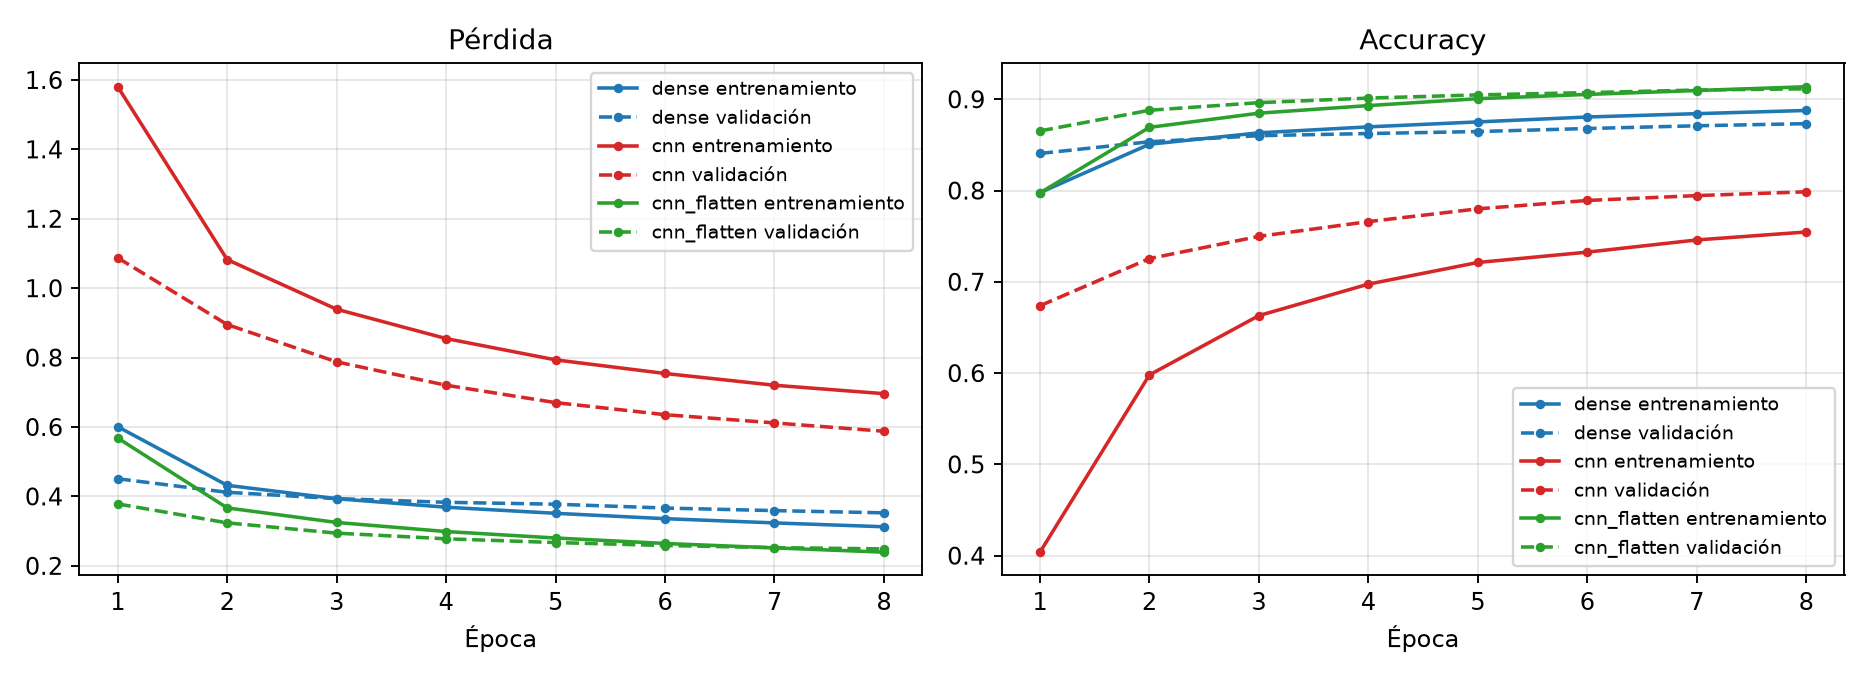

In [5]:
display(Image(REPORTS / 'training_curves.png', width=900))

Lectura: en `cnn` (GlobalAveragePooling) ambas pérdidas siguen bajando en la época 8 y la validación supera al entrenamiento por el Dropout: **subajuste**. `cnn_flatten` aprende mucho más rápido con los mismos filtros: promediar la posición de los rasgos era lo que limitaba a la CNN original.

## 4. Métricas y errores por clase

clase               dense          cnn  cnn_flatten recall cnn_fl
T-shirt/top         0.818        0.717        0.850         0.898
Trouser             0.974        0.959        0.983         0.980
Pullover            0.754        0.675        0.857         0.848
Dress               0.863        0.796        0.913         0.913
Coat                0.780        0.664        0.839         0.922
Sandal              0.951        0.916        0.978         0.992
Shirt               0.651        0.422        0.676         0.577
Sneaker             0.935        0.901        0.955         0.954
Bag                 0.960        0.926        0.979         0.981
Ankle boot          0.951        0.915        0.966         0.958


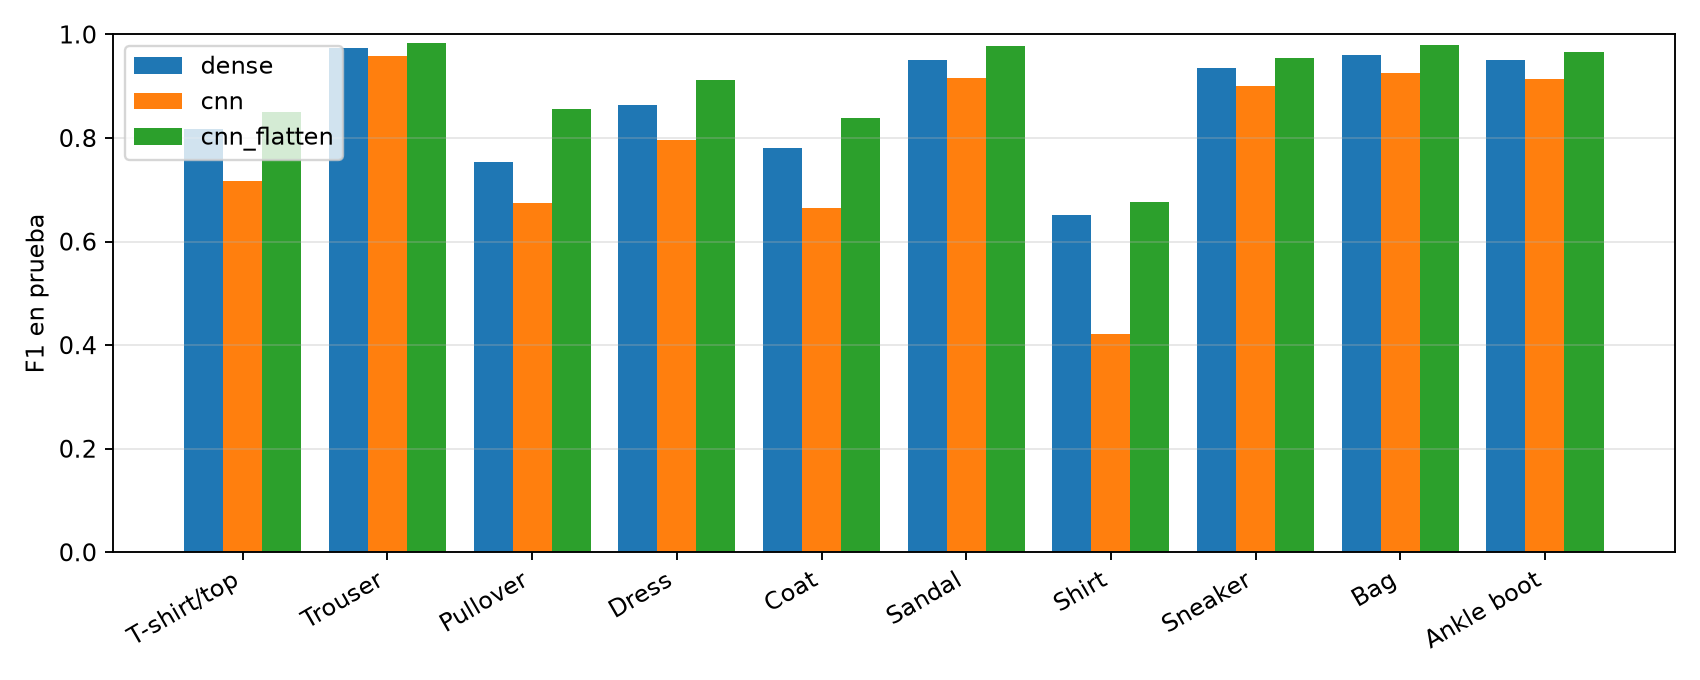

In [6]:
reports = json.loads((REPORTS / 'classification_reports.json').read_text())
print(f"{'clase':12s}" + ''.join(f'{n:>13s}' for n in NAMES) + f"{'recall cnn_fl':>14s}")
for label in CLASS_NAMES:
    print(f'{label:12s}' + ''.join(f"{reports[n][label]['f1-score']:13.3f}" for n in NAMES)
          + f"{reports['cnn_flatten'][label]['recall']:14.3f}")
display(Image(REPORTS / 'per_class_f1.png', width=850))

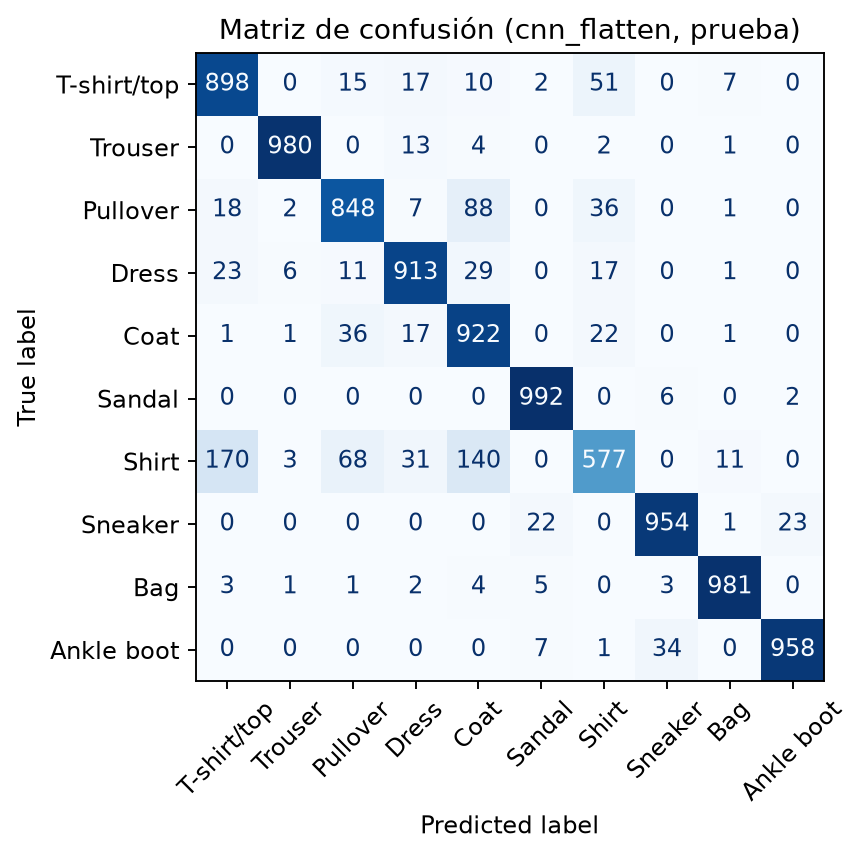

dense pares más confundidos:
   Pullover -> Coat: 184
   Shirt -> T-shirt/top: 162
   Shirt -> Coat: 109
cnn pares más confundidos:
   Shirt -> T-shirt/top: 274
   Pullover -> Coat: 159
   Shirt -> Coat: 135
cnn_flatten pares más confundidos:
   Shirt -> T-shirt/top: 170
   Shirt -> Coat: 140
   Pullover -> Coat: 88


In [7]:
display(Image(REPORTS / 'confusion_cnn_flatten.png', width=520))
for name in NAMES:
    print(name, 'pares más confundidos:')
    for pair in metrics[name]['top_confusions'][:3]:
        print(f"   {pair['true']} -> {pair['pred']}: {pair['count']}")

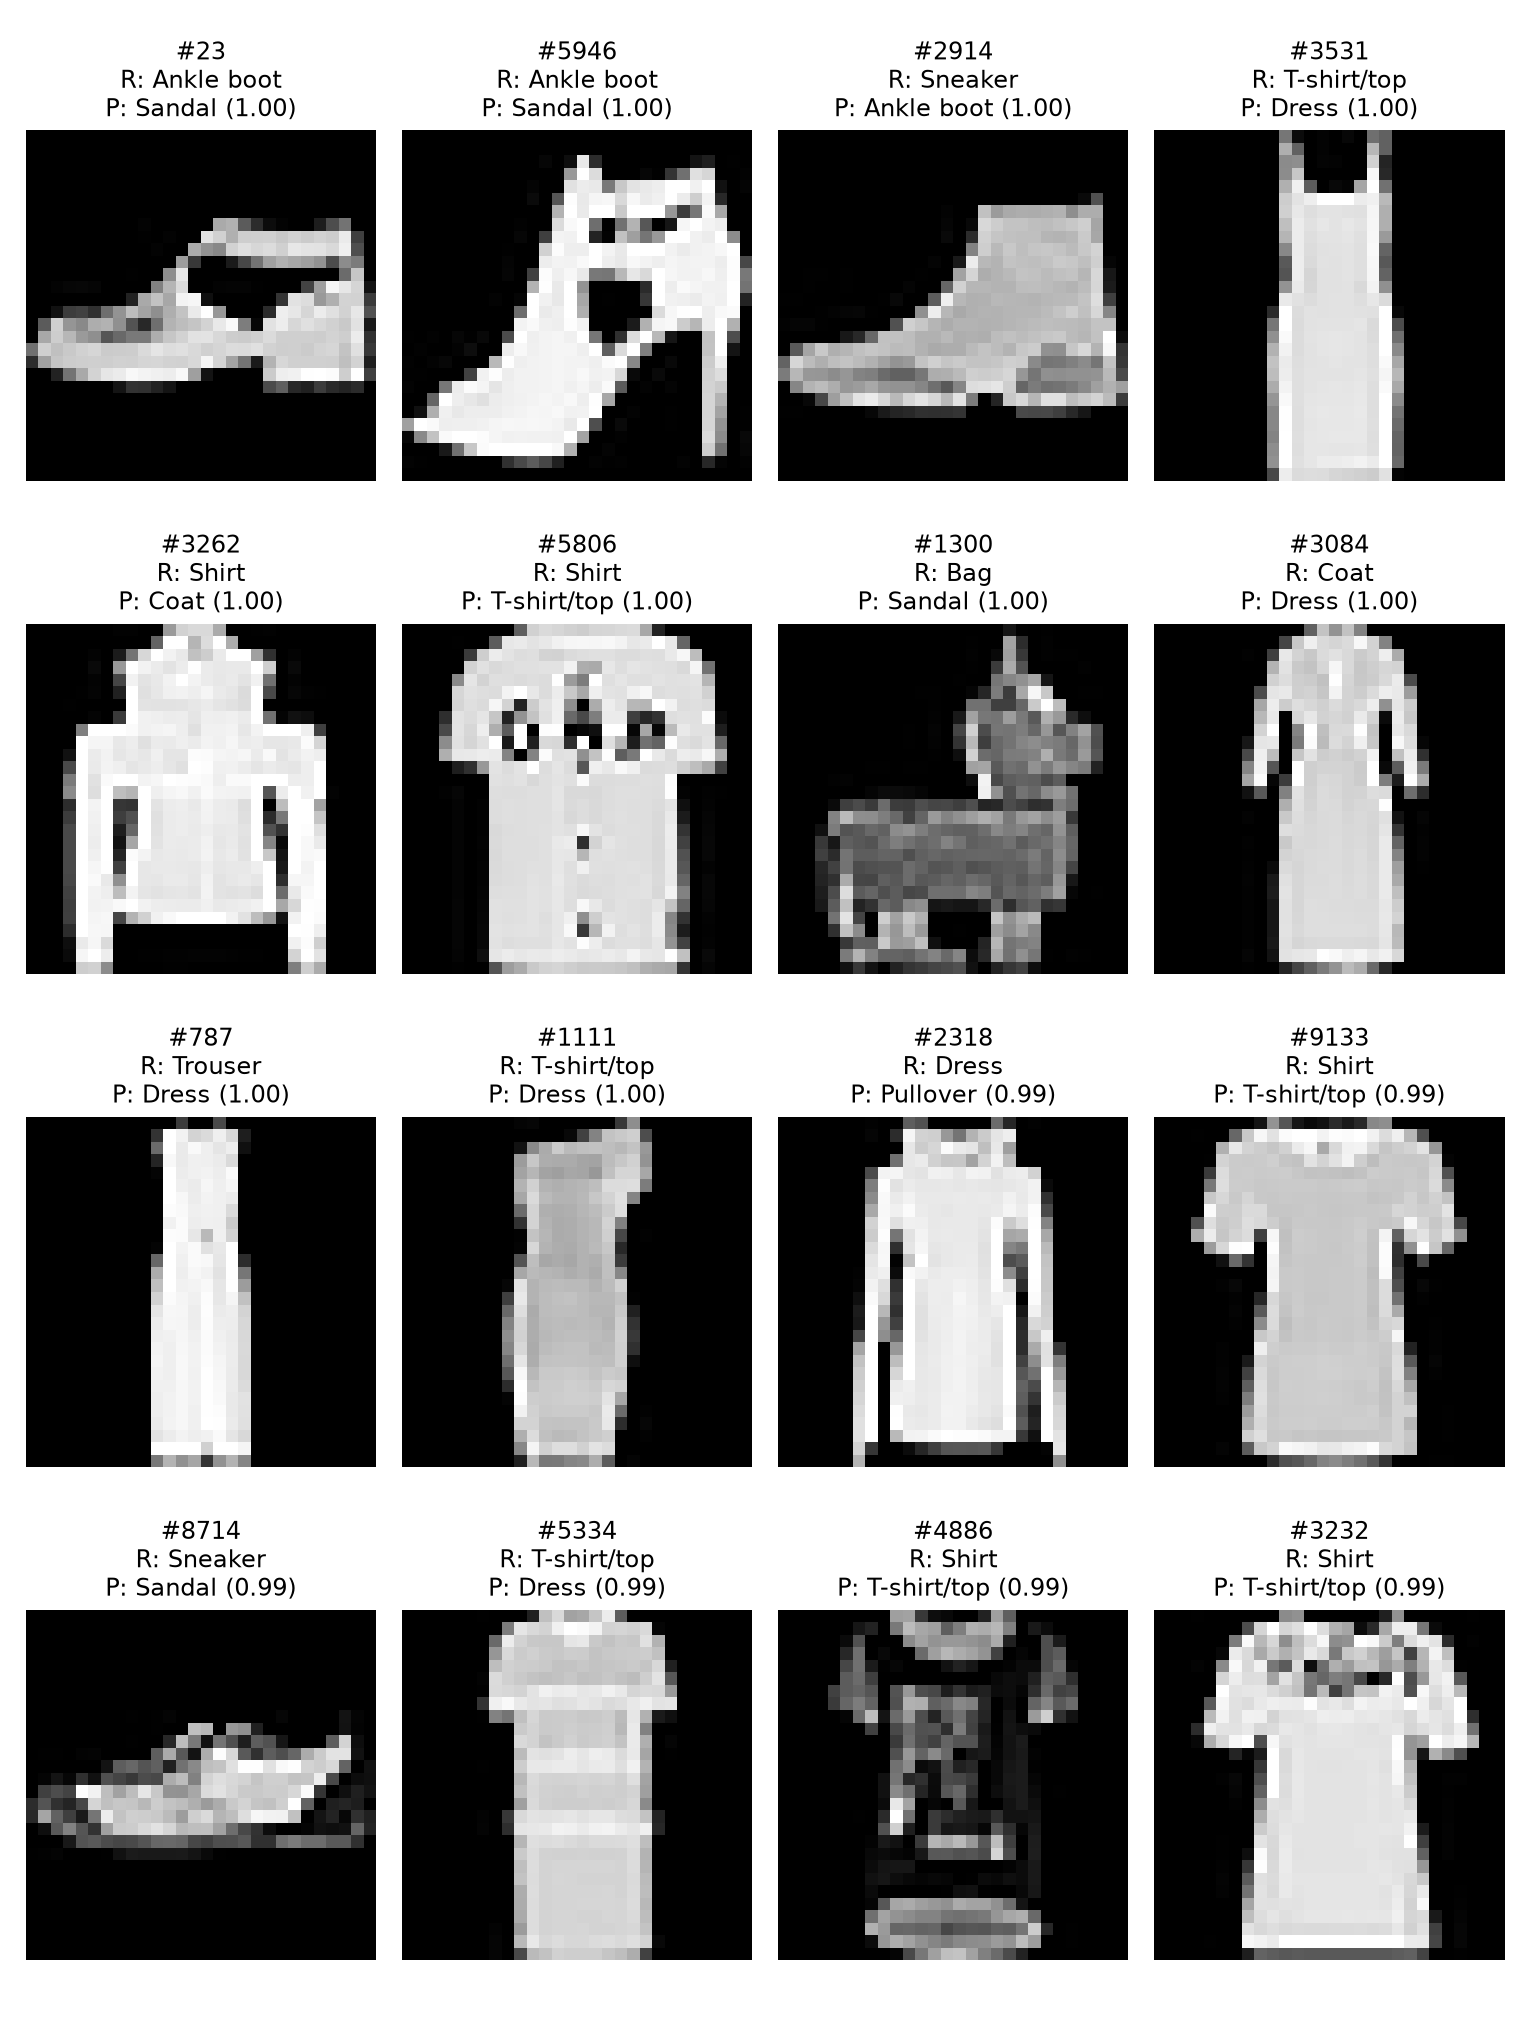

In [8]:
display(Image(REPORTS / 'cnn_flatten_errors.png', width=700))

Los 16 errores de mayor confianza de `cnn_flatten`. Se comparan clase real, predicción y forma de la prenda para encontrar pares visualmente semejantes y ejemplos ambiguos (ver informe y Model Card).

## 5. Costo: medición repetida de inferencia

In [9]:
for name, model in loaded.items():
    timing = measure_inference(model, x_test, repeats=5)
    print(f"{name:12s} mediana {timing['median_ms_per_image']:.4f} ms/img (desv. {timing['std_ms_per_image']:.4f}) sobre {timing['batch_images']} imágenes")

dense        mediana 0.0334 ms/img (desv. 0.0015) sobre 10000 imágenes


cnn          mediana 0.1027 ms/img (desv. 0.0016) sobre 10000 imágenes


cnn_flatten  mediana 0.0427 ms/img (desv. 0.0261) sobre 10000 imágenes


Los tiempos varían entre ejecuciones; se interpreta el orden relativo, no el valor absoluto.